<center><h1>Steven-Schneider_Isla_HW4</h1></center>
<br>
<br>

Name: Isla Steven-Schneider
<br>
Github Username: islastevenschneider
<br>
USC ID: 1985-4980-09

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.model_selection import StratifiedKFold, GridSearchCV
np.random.seed(1019)

Get the AReM Data Set

In [2]:
root = "AReM"
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
data = {}

for folder_name in os.listdir(root):
    folder_path = os.path.join(root, folder_name)
    if not os.path.isdir(folder_path):
        continue
    for file in os.listdir(folder_path):
        if not file.endswith(".csv"):
            continue
        num = int(file.replace("dataset", "").replace(".csv", ""))
        data[(folder_name, num)] = pd.read_csv(os.path.join(folder_path, file), skiprows=5, names=cols, usecols=range(7), sep=r"[,\s]+", engine="python")

### (b) Splitting Data

In [3]:
test_set = {}
train_set = {}

for (folder_name, num), df in data.items():
    if folder_name.startswith("bending"):
        max_test = 2
    else:
        max_test = 3
    if num <= max_test:
        test_set[(folder_name, num)] = df
    else:
        train_set[(folder_name, num)] = df

### (c) Feature Extraction

In [4]:
rows = []

for (folder_name, num), df in data.items():
    row = {"activity": folder_name, "dataset": num}
    for i, col in enumerate(cols[1:], start=1):
        series = df[col]
        row[f"min{i}"] = series.min()
        row[f"max{i}"] = series.max()
        row[f"mean{i}"] = series.mean()
        row[f"median{i}"] = series.median()
        row[f"std{i}"] = series.std()
        row[f"1st_quart{i}"] = series.quantile(0.25)
        row[f"3rd_quart{i}"] = series.quantile(0.75)
    rows.append(row)

features = pd.DataFrame(rows)
features = features.sort_values(["activity", "dataset"]).reset_index(drop=True)
features

,activity,dataset,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,bending1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,bending1,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,bending1,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,bending1,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking,11,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,walking,12,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,walking,13,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,walking,14,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

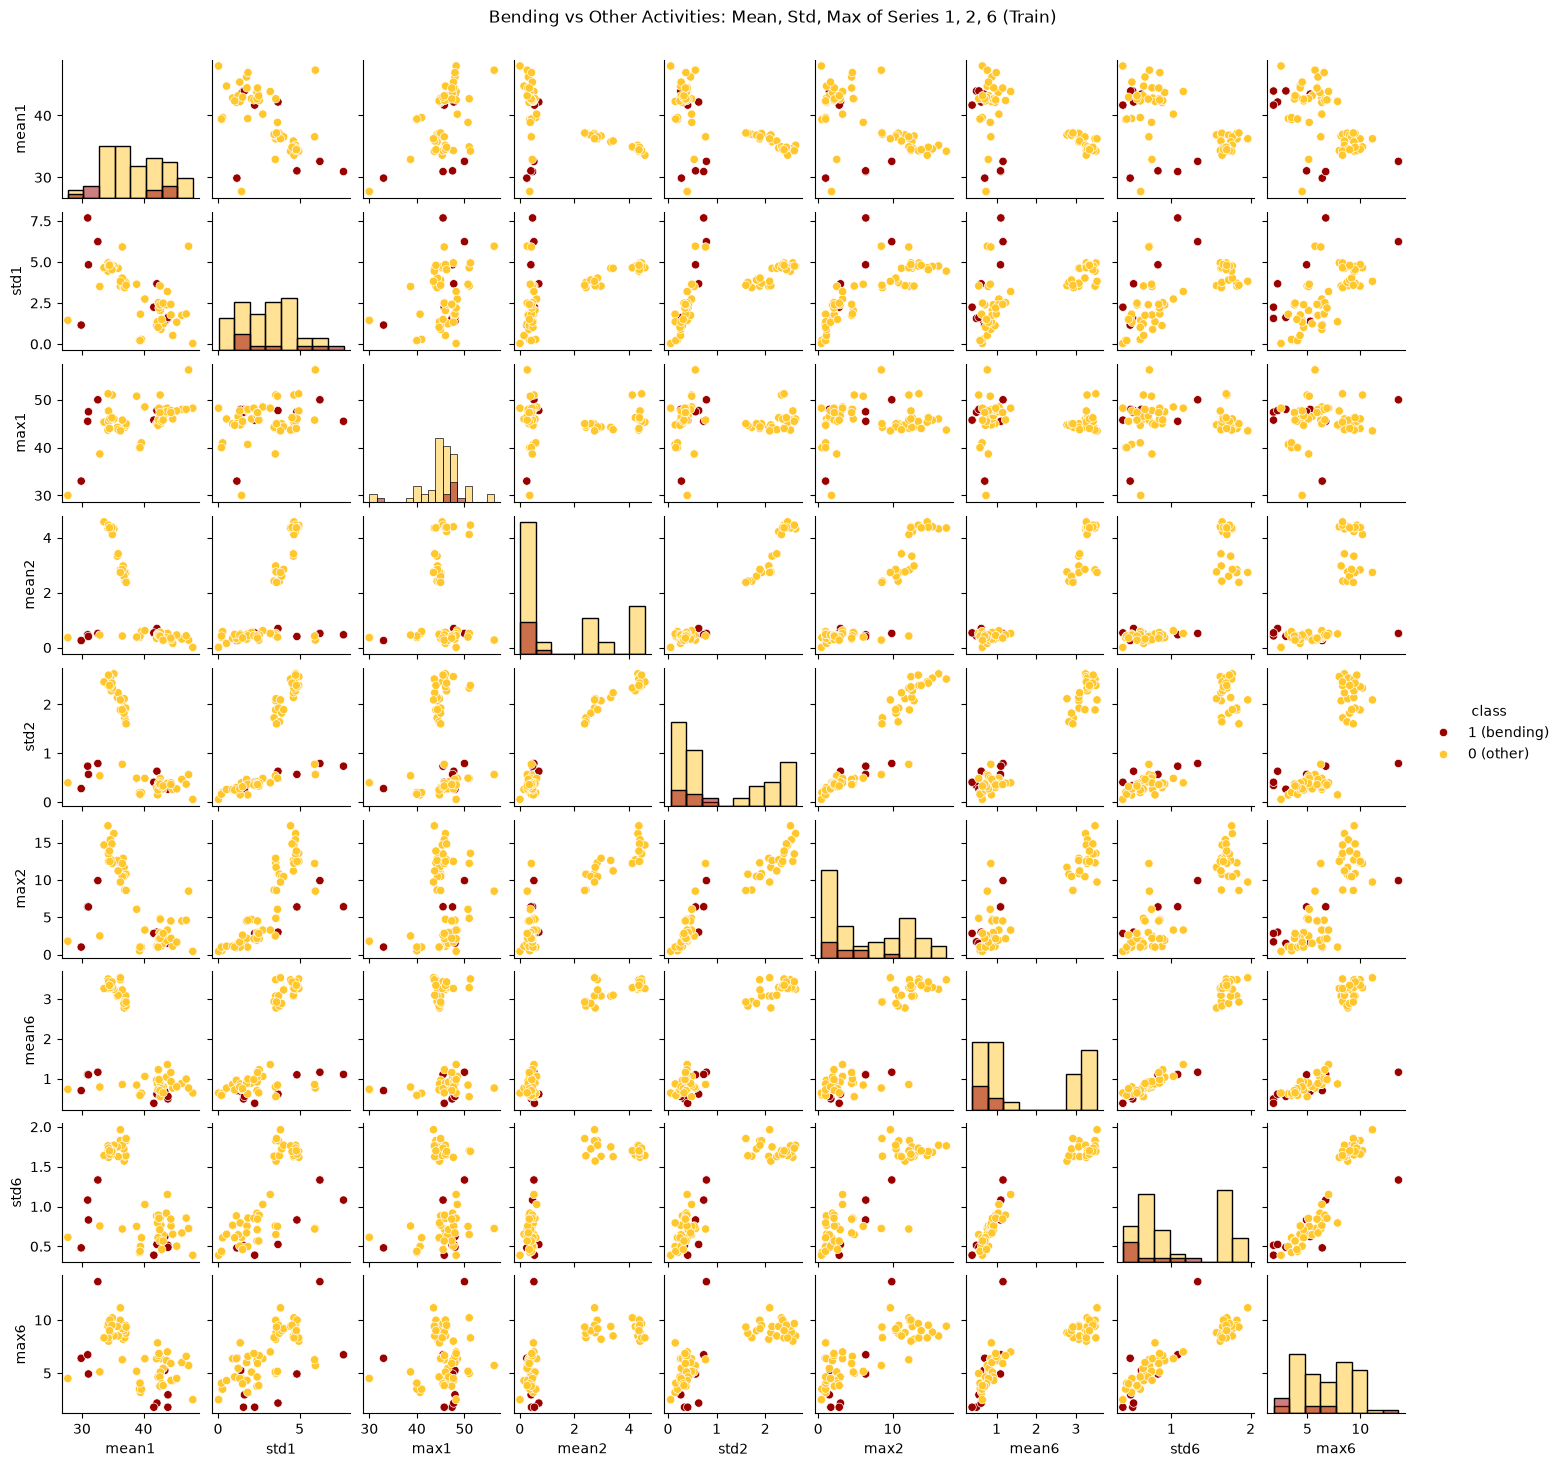

In [5]:
def compute_features(df, n_pieces=1):
    row = {}
    for i, col in enumerate(cols[1:], start=1):
        pieces = np.array_split(df[col].values, n_pieces)
        for k, piece in enumerate(pieces, start=1):
            s = pd.Series(piece)
            tag = f"{i}" if n_pieces == 1 else f"{i}_{k}"
            row[f"min{tag}"] = s.min()
            row[f"max{tag}"] = s.max()
            row[f"mean{tag}"] = s.mean()
            row[f"median{tag}"] = s.median()
            row[f"std{tag}"] = s.std()
            row[f"1st_quart{tag}"] = s.quantile(0.25)
            row[f"3rd_quart{tag}"] = s.quantile(0.75)
    return row

def features_table(dataset, n_pieces=1):
    rows = []
    for (activity, num), df in dataset.items():
        row = {"activity": activity, "dataset": num, "is_bending": int(activity.startswith("bending"))}
        row.update(compute_features(df, n_pieces))
        rows.append(row)
    return pd.DataFrame(rows).sort_values(["activity", "dataset"]).reset_index(drop=True)

colors = {"1 (bending)": "#990000", "0 (other)": "#FFC72C"}

train_df = features_table(train_set)
test_df = features_table(test_set)

chosen = ["mean", "std", "max"]
plot_series = [1, 2, 6]
plot_cols = [f"{f}{s}" for s in plot_series for f in chosen]

plot_df = train_df[plot_cols].copy()
plot_df["class"] = train_df["is_bending"].map({1: "1 (bending)", 0: "0 (other)"})

sns.pairplot(plot_df, hue="class", palette=colors, diag_kind="hist", height=1.6)
plt.suptitle("Bending vs Other Activities: Mean, Std, Max of Series 1, 2, 6 (Train)", y=1.02)
plt.show()

#### ii. Splitted Plots

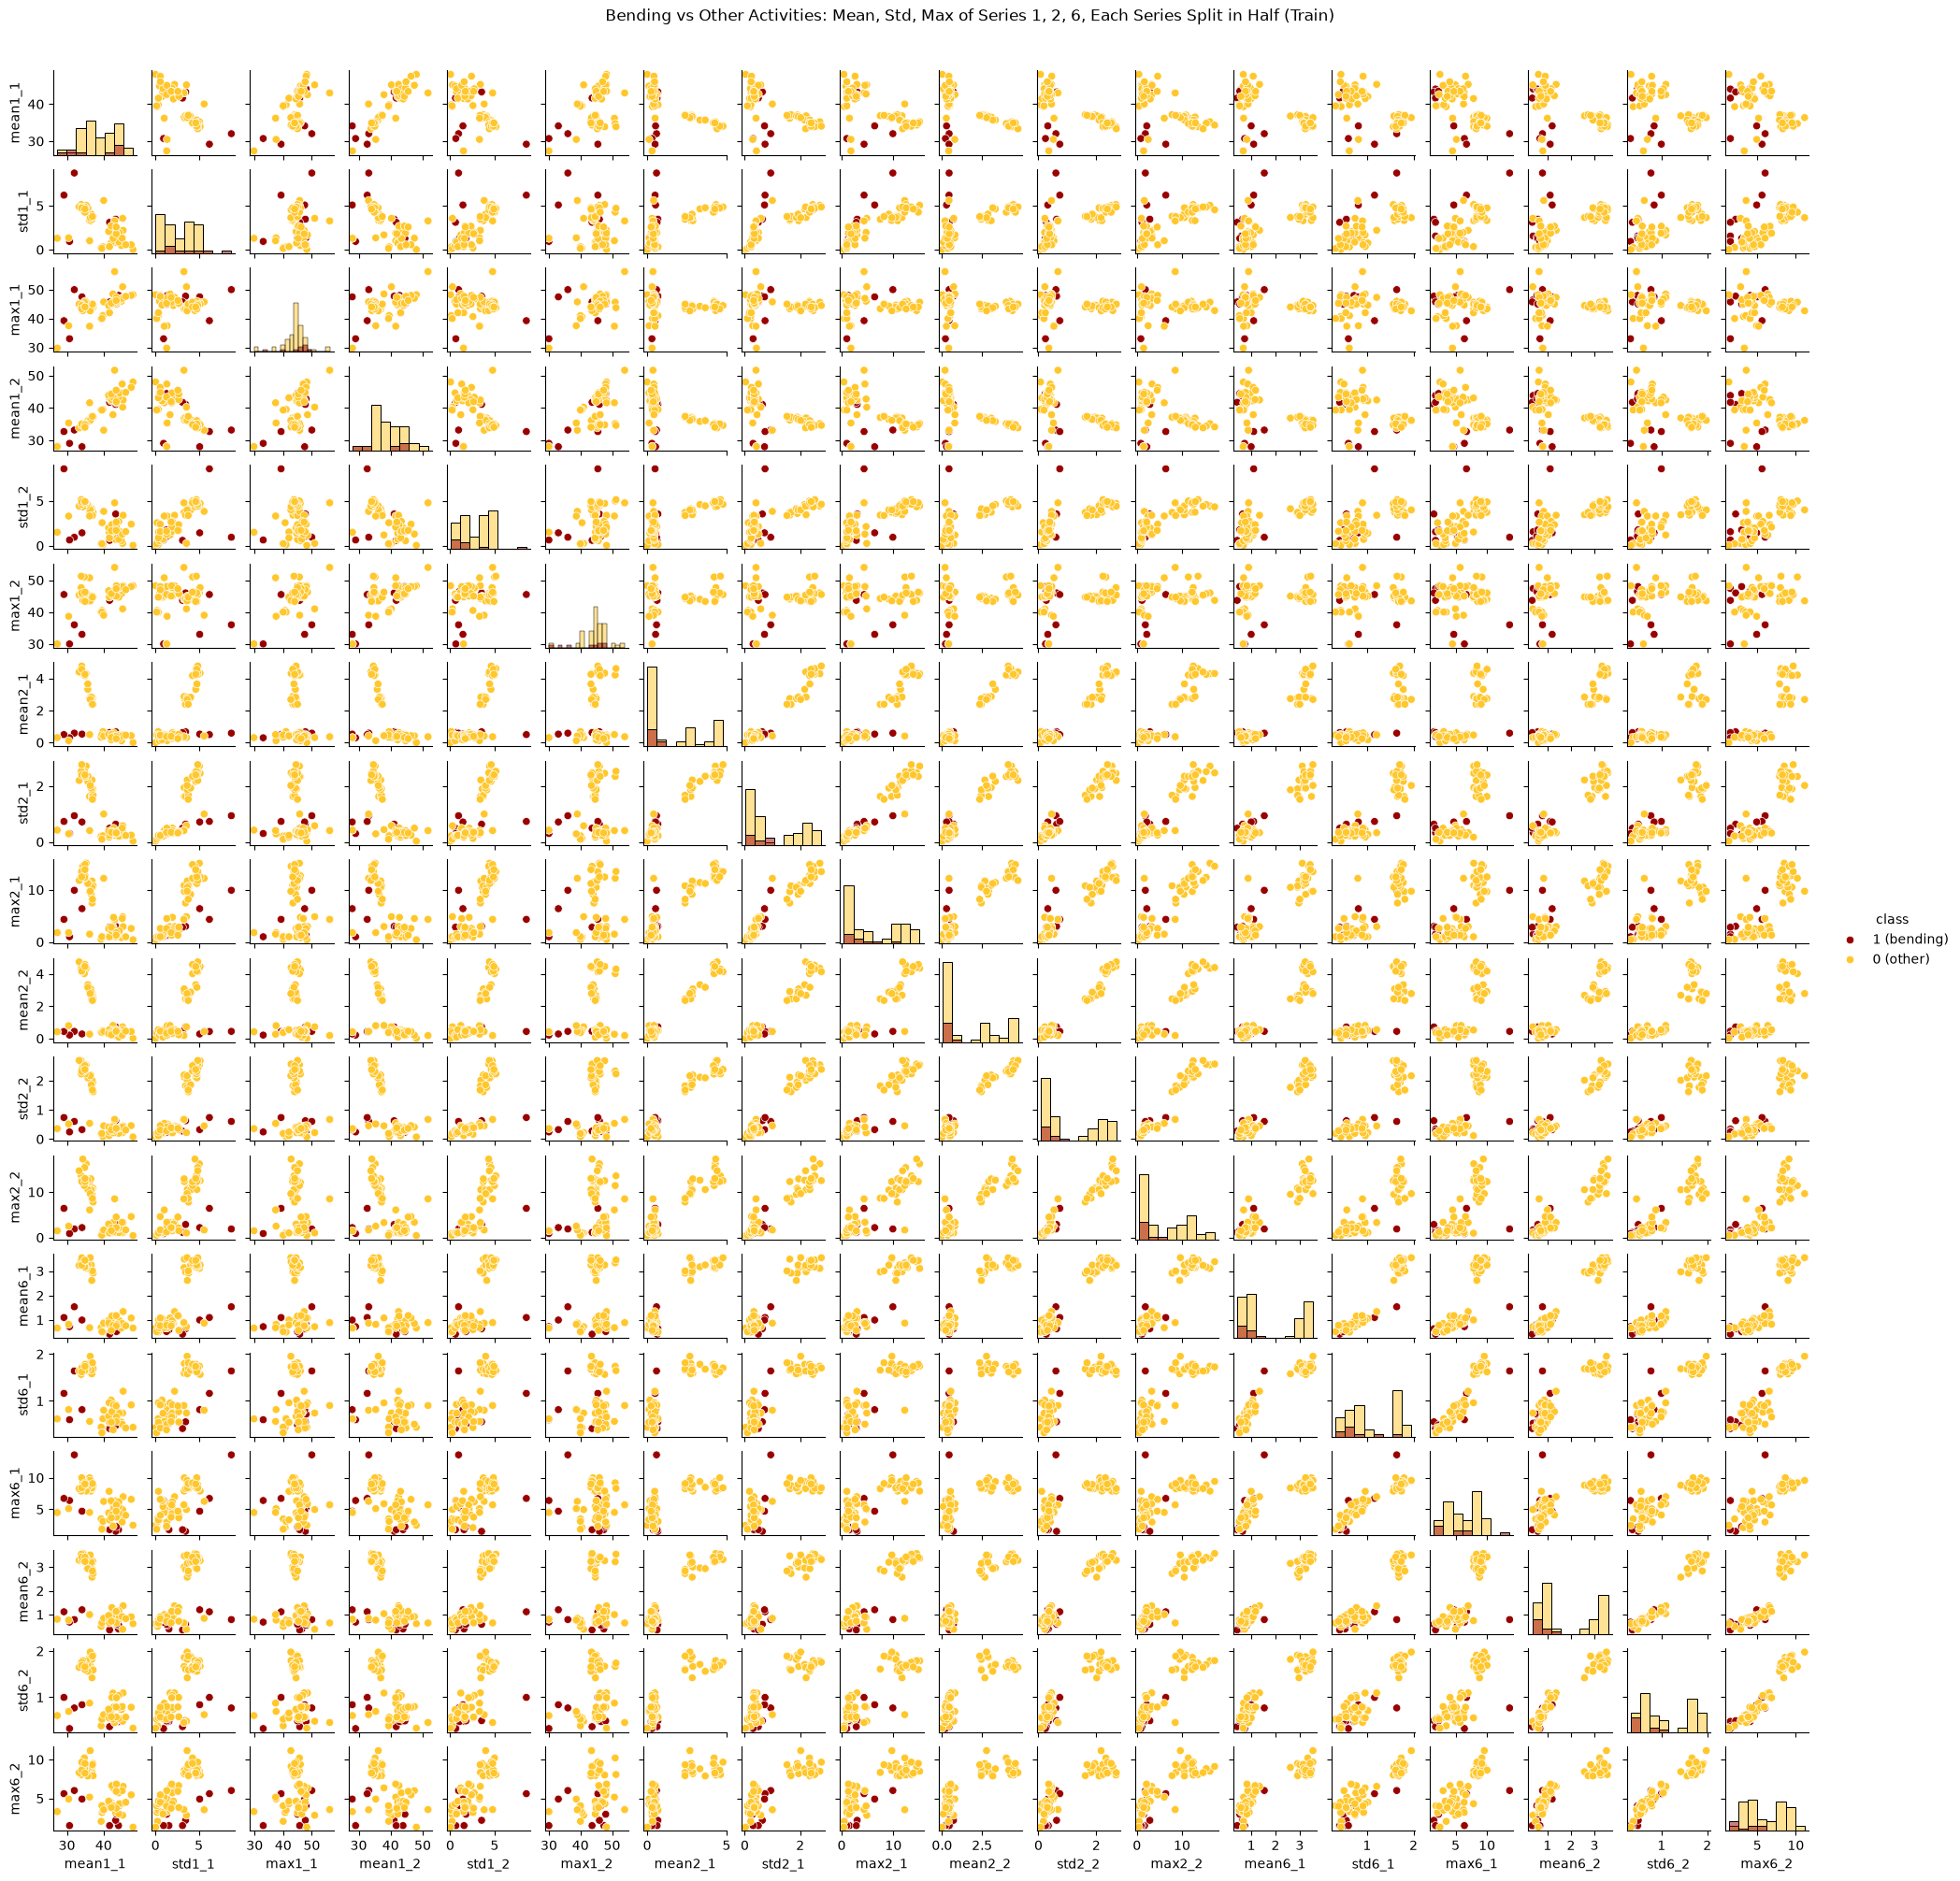

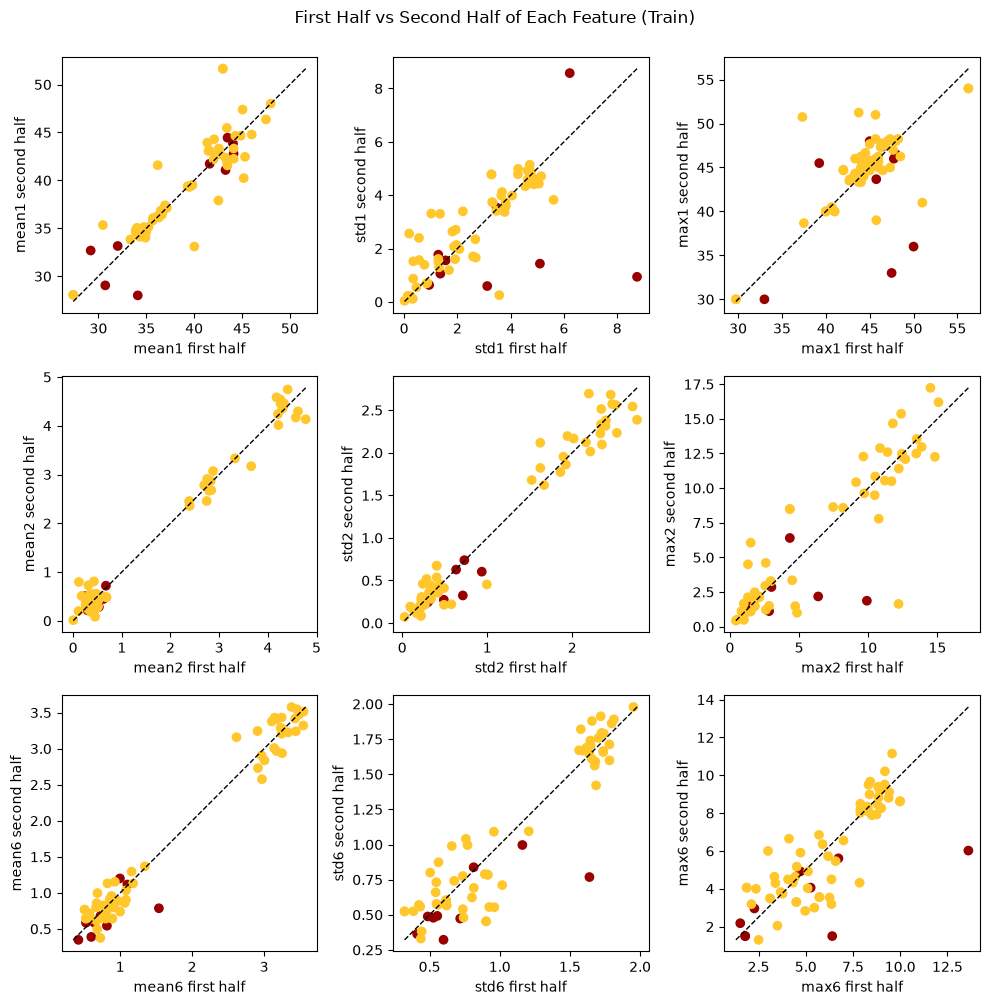

In [6]:
train_df2 = features_table(train_set, n_pieces=2)
test_df2 = features_table(test_set, n_pieces=2)

plot_cols2 = [f"{f}{s}_{k}" for s in plot_series for k in (1, 2) for f in chosen]

plot_df2 = train_df2[plot_cols2].copy()
plot_df2["class"] = train_df2["is_bending"].map({1: "1 (bending)", 0: "0 (other)"})

sns.pairplot(plot_df2, hue="class", palette=colors, diag_kind="hist", height=1.1)
plt.suptitle("Bending vs Other Activities: Mean, Std, Max of Series 1, 2, 6, Each Series Split in Half (Train)", y=1.02)
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
pairs = [(f, s) for s in plot_series for f in chosen]
for ax, (f, s) in zip(axes.flat, pairs):
    a, b = train_df2[f"{f}{s}_1"], train_df2[f"{f}{s}_2"]
    ax.scatter(a, b, c=train_df2["is_bending"].map({1: "#990000", 0: "#FFC72C"}))
    lim = [min(a.min(), b.min()), max(a.max(), b.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel(f"{f}{s} first half")
    ax.set_ylabel(f"{f}{s} second half")
plt.suptitle("First Half vs Second Half of Each Feature (Train)", y=1.0)
plt.tight_layout()
plt.show()

Breaking each time series into a first and second half does not make a considerable difference from the results in 2(a)i. The bending instances overlap with the other still activities in the same way, and in the panels that plot a first-half feature against its second-half feature the means sit on the diagonal almost exactly, while std and max scatter a little more, mostly for bending instances, so the two halves are giving nearly the same numbers. I was a little surprised by this. For an action like bending, where the first half is moving down and the second half is coming back up, I expected the whole-series features to average that out, since you start and end in the same position, and the split features to pick up the difference. However, this is not the case. The recordings look steady across both halves, so splitting in two mostly doubles the number of features without adding new information.

#### iii. Time Series Segments

l =  1: 42 features, best CV accuracy 0.971
l =  2: 84 features, best CV accuracy 0.956
l =  3: 126 features, best CV accuracy 0.956
l =  4: 168 features, best CV accuracy 0.971
l =  5: 210 features, best CV accuracy 0.957
l =  6: 252 features, best CV accuracy 0.957
l =  7: 294 features, best CV accuracy 0.942
l =  8: 336 features, best CV accuracy 0.942
l =  9: 378 features, best CV accuracy 0.971
l = 10: 420 features, best CV accuracy 0.971
l = 11: 462 features, best CV accuracy 0.971
l = 12: 504 features, best CV accuracy 0.957
l = 13: 546 features, best CV accuracy 0.971
l = 14: 588 features, best CV accuracy 0.943
l = 15: 630 features, best CV accuracy 0.971
l = 16: 672 features, best CV accuracy 0.956
l = 17: 714 features, best CV accuracy 0.956
l = 18: 756 features, best CV accuracy 0.971
l = 19: 798 features, best CV accuracy 0.971
l = 20: 840 features, best CV accuracy 0.986

Best pair: l* = 20, p* = 6, CV accuracy = 0.986


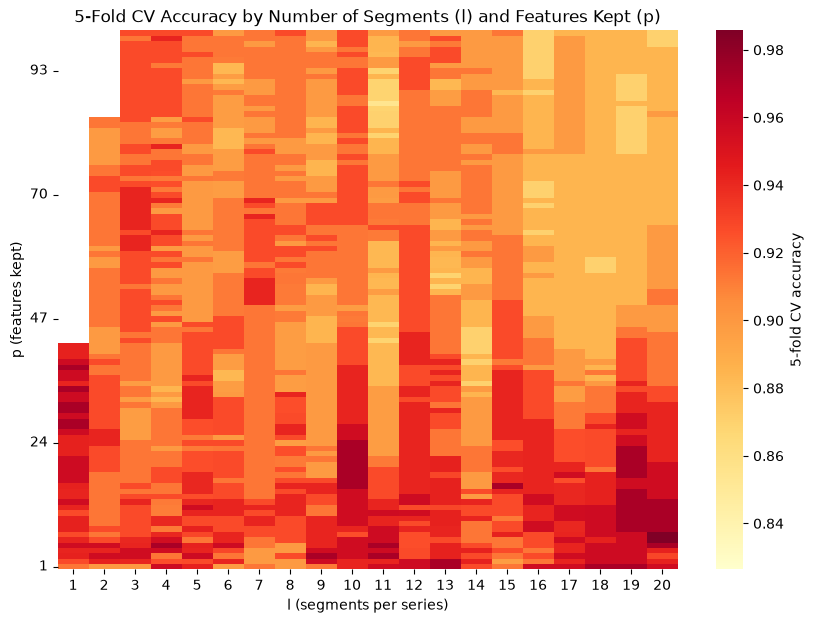

In [7]:
meta = ["activity", "dataset", "is_bending"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1019)
logreg = LogisticRegression(C=1e6, max_iter=200)

rows = []
for l in range(1, 21):
    df_l = features_table(train_set, n_pieces=l)
    X = df_l.drop(columns=meta).values
    y = df_l["is_bending"].values
    n_feat = X.shape[1]
    fold_acc = np.zeros((5, n_feat))
    for f, (tr, va) in enumerate(skf.split(X, y)):
        scaler = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler.transform(X[tr]), scaler.transform(X[va])
        rfe = RFE(logreg, n_features_to_select=1, step=1).fit(X_tr, y[tr])
        for p in range(1, n_feat + 1):
            keep = rfe.ranking_ <= p
            logreg.fit(X_tr[:, keep], y[tr])
            fold_acc[f, p - 1] = logreg.score(X_va[:, keep], y[va])
    for p in range(1, n_feat + 1):
        rows.append({"l": l, "p": p, "cv_accuracy": fold_acc[:, p - 1].mean()})
    print(f"l = {l:2d}: {n_feat} features, best CV accuracy {fold_acc.mean(axis=0).max():.3f}")

cv_table = pd.DataFrame(rows)
best = cv_table.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
l_star, p_star = int(best["l"]), int(best["p"])
print(f"\nBest pair: l* = {l_star}, p* = {p_star}, CV accuracy = {best['cv_accuracy']:.3f}")

heat = cv_table.pivot(index="p", columns="l", values="cv_accuracy")
plt.figure(figsize=(10, 7))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("5-Fold CV Accuracy by Number of Segments (l) and Features Kept (p)")
plt.xlabel("l (segments per series)")
plt.ylabel("p (features kept)")
plt.ylim(0, 100)
plt.show()

What separates the right way from the wrong way is which instances the recursive feature elimination is allowed to see. The wrong way is to run RFE on all 69 training instances, pick the best p features, and then cross-validate logistic regression on those features. The problem is that the held-out fold already influenced which features were chosen, so the model has effectively seen every instance and the CV accuracy comes out too optimistic, similar to overfitting. The right way is to hold out a fold first, run RFE on the remaining four folds only, fit on those features, and score on the held-out fold, repeating for each fold. That is what the code does. I also used stratified folds because only 9 of the 69 training instances are bending, so a random split could leave a fold with none.

The best pair was l* = 20 and p* = 6 with a CV accuracy of 0.986. The accuracy is nearly flat across l (most reach 0.971), so the number of segments barely matters, which matches 2(a)ii where the two halves looked the same. Small p consistently beats large p in the heatmap: with 69 instances, keeping hundreds of features overfits, and a handful of selected features generalizes better. Most values of l are within one instance of the best, and models with nearly equal CV error are roughly equivalent in test error, so l = 20 should not be read as evidence that 20 segments are needed. The heatmap is cropped to p ≤ 100 since accuracy is flat beyond that.

#### iv. Confusion Matrix

Selected features: ['max1_14', 'std3_16', 'mean5_3', 'median5_3', '1st_quart5_3', 'min5_18']

Confusion matrix (train):
                predicted other  predicted bending
actual other                 60                  0
actual bending                0                  9

Train AUC: 1.000


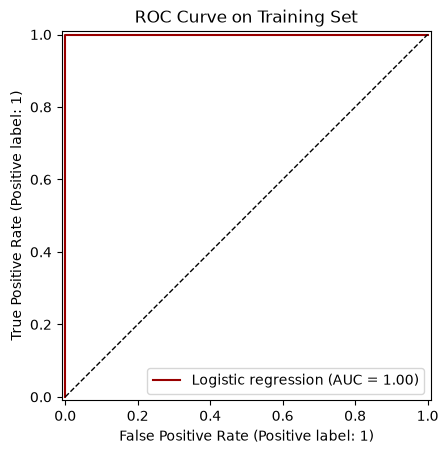

/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/statsmodels/base/optimizer.py:536: PerfectS

,beta,std err,p-value
const,-36.955126,5.200322e+05,0.999943
max1_14,-8.712204,4.890821e+05,0.999986
std3_16,-11.613322,4.502939e+05,0.999979
mean5_3,42.724302,8.752627e+06,0.999996
median5_3,-33.907235,1.173392e+07,0.999998
1st_quart5_3,22.826319,3.417302e+06,0.999995
min5_18,7.634295,7.603385e+05,0.999992


In [8]:
train_star = features_table(train_set, n_pieces=l_star)
test_star = features_table(test_set, n_pieces=l_star)
feat_names = train_star.drop(columns=meta).columns

X_train = train_star[feat_names].values
y_train = train_star["is_bending"].values

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)

rfe_star = RFE(logreg, n_features_to_select=p_star, step=1).fit(X_train_s, y_train)
selected = feat_names[rfe_star.support_]
print("Selected features:", list(selected))

final_model = LogisticRegression(C=1e6, max_iter=200).fit(X_train_s[:, rfe_star.support_], y_train)
y_pred = final_model.predict(X_train_s[:, rfe_star.support_])
y_prob = final_model.predict_proba(X_train_s[:, rfe_star.support_])[:, 1]

cm = pd.DataFrame(confusion_matrix(y_train, y_pred),
                  index=["actual other", "actual bending"],
                  columns=["predicted other", "predicted bending"])
print("\nConfusion matrix (train):")
print(cm)
print(f"\nTrain AUC: {roc_auc_score(y_train, y_prob):.3f}")

RocCurveDisplay.from_predictions(y_train, y_prob, name="Logistic regression", curve_kwargs={"color": "#990000"})
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.title("ROC Curve on Training Set")
plt.show()

X_sm = sm.add_constant(pd.DataFrame(X_train_s[:, rfe_star.support_], columns=selected))
logit_sm = sm.Logit(y_train, X_sm).fit(disp=0, maxiter=200)
coef_table = pd.DataFrame({"beta": logit_sm.params, "std err": logit_sm.bse, "p-value": logit_sm.pvalues})
coef_table

#### v. Test Classifier

In [9]:
X_test = test_star[feat_names].values
y_test = test_star["is_bending"].values
X_test_s = scaler.transform(X_test)[:, rfe_star.support_]

y_test_pred = final_model.predict(X_test_s)
y_test_prob = final_model.predict_proba(X_test_s)[:, 1]

cm_test = pd.DataFrame(confusion_matrix(y_test, y_test_pred),
                       index=["actual other", "actual bending"],
                       columns=["predicted other", "predicted bending"])
print("Confusion matrix (test):")
print(cm_test)
print(f"\nTest accuracy: {(y_test_pred == y_test).mean():.3f}")
print(f"Test AUC: {roc_auc_score(y_test, y_test_prob):.3f}")
print(f"CV accuracy from 2(a)iii: {best['cv_accuracy']:.3f}")

Confusion matrix (test):
                predicted other  predicted bending
actual other                 15                  0
actual bending                1                  3

Test accuracy: 0.947
Test AUC: 0.983
CV accuracy from 2(a)iii: 0.986


On the test set the classifier gets 18 of 19 instances right, an accuracy of 0.947 with an AUC of 0.983. All 15 non-bending instances are correct and 3 of the 4 bending instances are, with one bending instance missed. This is a bit below the CV accuracy of 0.986 from 2(a)iii. That makes sense: the CV number was used to pick l and p, so it is slightly optimistic, and with only 19 test instances one mistake is about 5%. The miss is on the rare class, which fits the imbalance in training, where only 9 of 69 instances are bending.

#### vi. Separation

Yes, the training classes are well separated on the six selected features, and this does cause instability. When fitting the final model with statsmodels I am given many warnings about perfect separation. The coefficients kept growing in magnitude, the standard errors were on the order of 10^5 to 10^7, and every p-value was close to 1. That is the signature of separable classes in logistic regression: if a line separates the two classes exactly, the likelihood keeps increasing as the coefficients grow, so the maximum likelihood estimates do not converge and the standard errors are meaningless. The confusion matrix on the training set backs this up, since the model classifies the training data essentially perfectly. Footnote 5 suggests limiting max_iter to stop the algorithm early, which is why the sklearn coefficients are finite.

#### vii. Imbalance

Confusion matrix (train), case-control model:
                predicted other  predicted bending
actual other                 60                  0
actual bending                0                  9
AUC (train): 1.000

Confusion matrix (test), case-control model:
                predicted other  predicted bending
actual other                 15                  0
actual bending                1                  3
AUC (test): 1.000



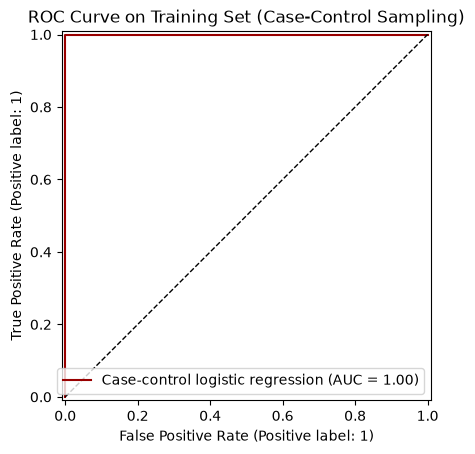

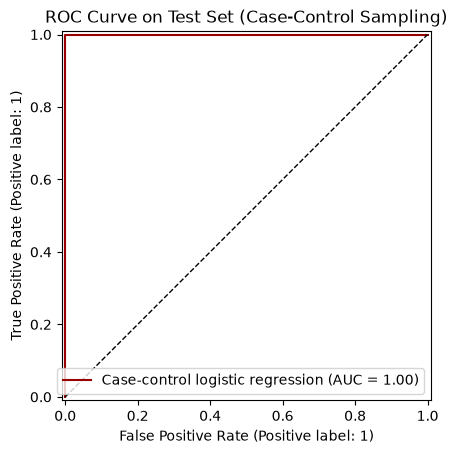

In [10]:
rng = np.random.default_rng(1019)
Xb = X_train_s[:, rfe_star.support_]

bend_idx = np.where(y_train == 1)[0]
other_idx = rng.choice(np.where(y_train == 0)[0], size=len(bend_idx), replace=False)
cc_idx = np.concatenate([bend_idx, other_idx])

case_control_model = LogisticRegression(C=1e6, max_iter=200).fit(Xb[cc_idx], y_train[cc_idx])

pi1 = y_train.mean()
pi1_cc = y_train[cc_idx].mean()
case_control_model.intercept_ += np.log(pi1 / (1 - pi1)) - np.log(pi1_cc / (1 - pi1_cc))

for name, X_, y_ in [("train", Xb, y_train), ("test", X_test_s, y_test)]:
    pred = case_control_model.predict(X_)
    prob = case_control_model.predict_proba(X_)[:, 1]
    cm_cc = pd.DataFrame(confusion_matrix(y_, pred),
                         index=["actual other", "actual bending"],
                         columns=["predicted other", "predicted bending"])
    print(f"Confusion matrix ({name}), case-control model:")
    print(cm_cc)
    print(f"AUC ({name}): {roc_auc_score(y_, prob):.3f}\n")

for name, X_, y_ in [("Training", Xb, y_train), ("Test", X_test_s, y_test)]:
    RocCurveDisplay.from_predictions(y_, case_control_model.predict_proba(X_)[:, 1], name="Case-control logistic regression", curve_kwargs={"color": "#990000"})
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.title(f"ROC Curve on {name} Set (Case-Control Sampling)")
    plt.show()

Yes, the classes are definitely imbalanced: 9 bending vs 60 other in the training set and 4 bending vs 15 other in the test set. To deal with this I made a case-control sample where the two classes have the same size, keeping all 9 bending instances and randomly drawing 9 of the 60 other instances. I then fit logistic regression on those 18 instances using the same six features and corrected the intercept with the case-control intercept adjustment, so the predicted probabilities reflect the true 9 out of 69 prior instead of the 50/50 sample. With this correction the model classifies the training set perfectly with an AUC of 1.0, and gets 18 out of 19 on the test set, also with an AUC of 1.0. The missed bending instance has a higher predicted probability than every non-bending instance, which is why the test AUC is 1.0, but it falls under the 0.5 cutoff. Lowering the threshold, would recover it at the cost of some false positives.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
C_grid = np.logspace(-2, 3, 20)
rows = []
for l in range(1, 21):
    df_l = features_table(train_set, n_pieces=l)
    X = df_l.drop(columns=meta).values
    y = df_l["is_bending"].values
    pipe = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000))
    search = GridSearchCV(pipe, {"logisticregression__C": C_grid}, cv=skf, scoring="accuracy").fit(X, y)
    n_nonzero = int((search.best_estimator_[-1].coef_ != 0).sum())
    rows.append({"l": l, "C": search.best_params_["logisticregression__C"], "cv_accuracy": search.best_score_, "n_nonzero": n_nonzero})
    print(f"l = {l:2d}: best C = {rows[-1]['C']:.3g}, CV accuracy {rows[-1]['cv_accuracy']:.3f}, nonzero coefs {n_nonzero}")

cv_table_lasso = pd.DataFrame(rows)
best_lasso_row = cv_table_lasso.sort_values(["cv_accuracy", "n_nonzero", "l"], ascending=[False, True, True]).iloc[0]
l_star_lasso, C_star_lasso = int(best_lasso_row["l"]), best_lasso_row["C"]
print(f"\nBest: l* = {l_star_lasso}, C* = {C_star_lasso:.3g}, CV accuracy = {best_lasso_row['cv_accuracy']:.3f}")

train_lasso = features_table(train_set, n_pieces=l_star_lasso)
test_lasso = features_table(test_set, n_pieces=l_star_lasso)
feat_lasso = train_lasso.drop(columns=meta).columns
scaler_lasso = StandardScaler().fit(train_lasso[feat_lasso].values)
Xtr_lasso = scaler_lasso.transform(train_lasso[feat_lasso].values)
Xte_lasso = scaler_lasso.transform(test_lasso[feat_lasso].values)
ytr_lasso, yte_lasso = train_lasso["is_bending"].values, test_lasso["is_bending"].values

final_model_lasso = LogisticRegression(C=C_star_lasso, l1_ratio=1, solver="liblinear", max_iter=1000).fit(Xtr_lasso, ytr_lasso)
kept = feat_lasso[final_model_lasso.coef_[0] != 0]
print(f"\nFeatures with nonzero coefficients ({len(kept)}):", list(kept))

for name, X_, y_ in [("train", Xtr_lasso, ytr_lasso), ("test", Xte_lasso, yte_lasso)]:
    pred = final_model_lasso.predict(X_)
    prob = final_model_lasso.predict_proba(X_)[:, 1]
    cm_l = pd.DataFrame(confusion_matrix(y_, pred), index=["actual other", "actual bending"], columns=["predicted other", "predicted bending"])
    print(f"\nConfusion matrix ({name}), L1 model:")
    print(cm_l)
    print(f"Accuracy ({name}): {(pred == y_).mean():.3f}   AUC ({name}): {roc_auc_score(y_, prob):.3f}")

l =  1: best C = 0.379, CV accuracy 0.986, nonzero coefs 4
l =  2: best C = 88.6, CV accuracy 0.970, nonzero coefs 12
l =  3: best C = 0.379, CV accuracy 0.971, nonzero coefs 7
l =  4: best C = 0.379, CV accuracy 0.929, nonzero coefs 8
l =  5: best C = 2.34, CV accuracy 0.943, nonzero coefs 12
l =  6: best C = 162, CV accuracy 0.943, nonzero coefs 28
l =  7: best C = 0.695, CV accuracy 0.943, nonzero coefs 10
l =  8: best C = 0.695, CV accuracy 0.943, nonzero coefs 14
l =  9: best C = 0.379, CV accuracy 0.943, nonzero coefs 10
l = 10: best C = 48.3, CV accuracy 0.957, nonzero coefs 27
l = 11: best C = 4.28, CV accuracy 0.957, nonzero coefs 11
l = 12: best C = 0.379, CV accuracy 0.971, nonzero coefs 5
l = 13: best C = 0.207, CV accuracy 0.943, nonzero coefs 6
l = 14: best C = 0.695, CV accuracy 0.971, nonzero coefs 12
l = 15: best C = 546, CV accuracy 0.957, nonzero coefs 89
l = 16: best C = 298, CV accuracy 0.942, nonzero coefs 64
l = 17: best C = 48.3, CV accuracy 0.957, nonzero coefs

#### ii. Comparison

The L1 model performs marginally better than the p-value model. It gets all 19 test instances correct with an AUC of 1.0, whereas the RFE model misses an instance, giving an accuracy of 0.947 with an AUC of 0.983. Both have the same CV accuracy of 0.986, but the L1 model got there with l = 1 and only 4 nonzero coefficients, compared to l = 20 and 6 features for RFE.

The L1 model is also the easier one to implement. This is because the penalty handles variable selection by itself, setting coefficients to zero, and GridSearchCV cross-validates C automatically, with standardization done inside each fold, so the whole search over l and C is a ten-line for loop. In the RFE method there is a separate loop over p inside every fold, and then you have to refit with statsmodels to get the p-values, which ended up being uninformative anyway because the classes are separable. Therefore, it is a lot more work for a slightly worse result.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l =  1: best C = 1.27, CV accuracy 0.900


/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l =  2: best C = 48.3, CV accuracy 0.885


/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


...

l = 18: best C = 48.3, CV accuracy 0.868


/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l = 19: best C = 48.3, CV accuracy 0.869


/Users/isla/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l = 20: best C = 1.27, CV accuracy 0.884

Best: l* = 1, C* = 1.27, CV accuracy = 0.900

l = 1, C = 1.27, nonzero coefficients = 27
Test error: 0.105

Confusion matrix (test), rows = actual, columns = predicted:
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      1        0         2        0
walking          0         0        0      0        0         0        3


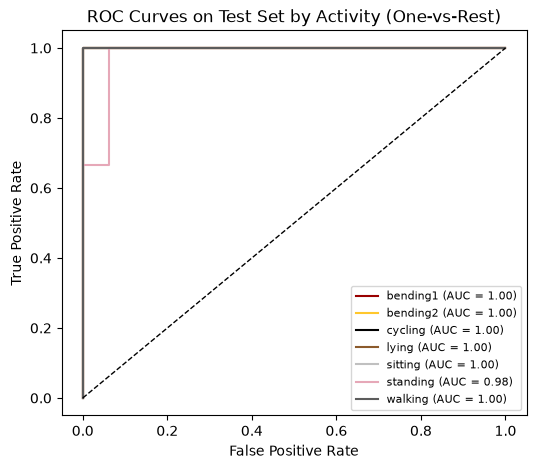

Macro-average AUC: 0.997


In [12]:
rows = []
for l in range(1, 21):
    df_l = features_table(train_set, n_pieces=l)
    X = df_l.drop(columns=meta).values
    y = df_l["activity"].values
    pipe = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", max_iter=2000, tol=1e-3, random_state=1019))
    search = GridSearchCV(pipe, {"logisticregression__C": C_grid}, cv=skf, scoring="accuracy", n_jobs=-1).fit(X, y)
    rows.append({"l": l, "C": search.best_params_["logisticregression__C"], "cv_accuracy": search.best_score_})
    print(f"l = {l:2d}: best C = {rows[-1]['C']:.3g}, CV accuracy {rows[-1]['cv_accuracy']:.3f}")

cv_table_multi = pd.DataFrame(rows)
best_multi_row = cv_table_multi.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
l_multi, C_multi = int(best_multi_row["l"]), best_multi_row["C"]
print(f"\nBest: l* = {l_multi}, C* = {C_multi:.3g}, CV accuracy = {best_multi_row['cv_accuracy']:.3f}\n")

train_multi = features_table(train_set, n_pieces=l_multi)
test_multi = features_table(test_set, n_pieces=l_multi)
feat_multi = train_multi.drop(columns=meta).columns
activities = sorted(train_multi["activity"].unique())

scaler_multi = StandardScaler().fit(train_multi[feat_multi].values)
Xtr_multi = scaler_multi.transform(train_multi[feat_multi].values)
Xte_multi = scaler_multi.transform(test_multi[feat_multi].values)
ytr_multi, yte_multi = train_multi["activity"].values, test_multi["activity"].values

multinomial_model = LogisticRegression(C=C_multi, l1_ratio=1, solver="saga", max_iter=5000, random_state=1019).fit(Xtr_multi, ytr_multi)

pred_multi = multinomial_model.predict(Xte_multi)
prob_multi = multinomial_model.predict_proba(Xte_multi)
print(f"l = {l_multi}, C = {C_multi:.3g}, nonzero coefficients = {int((multinomial_model.coef_ != 0).sum())}")
print(f"Test error: {(pred_multi != yte_multi).mean():.3f}\n")

cm_multi = pd.DataFrame(confusion_matrix(yte_multi, pred_multi, labels=activities), index=activities, columns=activities)
print("Confusion matrix (test), rows = actual, columns = predicted:")
print(cm_multi)

activity_colors = {"bending1": "#990000", "bending2": "#FFC72C", "cycling": "#000000", "lying": "#8B5A2B",
                   "sitting": "#C0C0C0", "standing": "#E6A8B8", "walking": "#5C5C5C"}

yte_bin = label_binarize(yte_multi, classes=activities)
plt.figure(figsize=(6, 5))
for k, act in enumerate(activities):
    fpr, tpr, _ = roc_curve(yte_bin[:, k], prob_multi[:, k])
    plt.plot(fpr, tpr, color=activity_colors[act], label=f"{act} (AUC = {roc_auc_score(yte_bin[:, k], prob_multi[:, k]):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves on Test Set by Activity (One-vs-Rest)")
plt.legend(loc="lower right", fontsize=8)
plt.show()
print(f"Macro-average AUC: {roc_auc_score(yte_bin, prob_multi, average='macro'):.3f}")

The confusion matrix generalizes directly to 7×7 with rows actual and columns predicted. ROC is binary by construction, so for 7 classes I use one-vs-rest: class k is positive and the other six are negative, scored by the predicted probability of class k. The macro-average AUC is the unweighted mean of the seven per-class AUCs. Although one caveat is that bending2 has only 4 training instances, so with 5 folds one fold contains none of it, and the CV estimate for that class is less reliable than for the others.

#### ii. Naive Bayes

Gaussian Naive Bayes: test error = 0.105
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      2        1         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


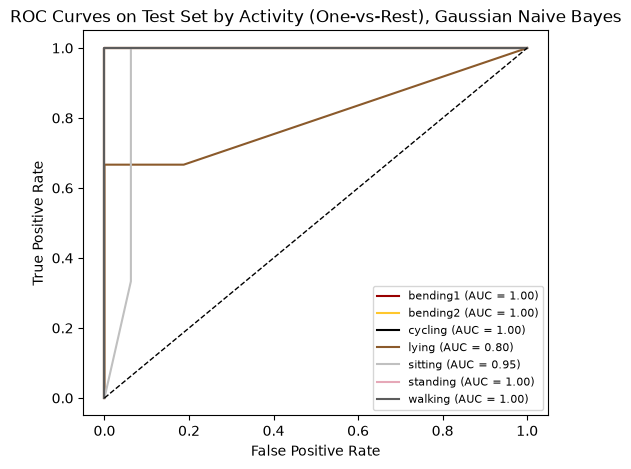

Macro-average AUC: 0.964

Multinomial Naive Bayes: test error = 0.211
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        1      2        0         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


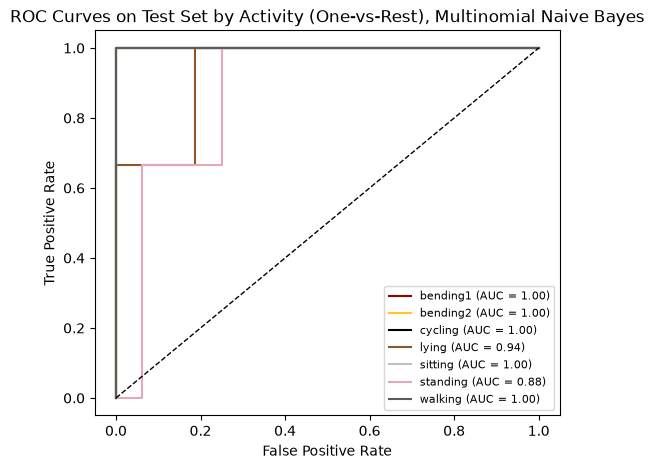

Macro-average AUC: 0.973



In [13]:
gaussian_model = GaussianNB().fit(Xtr_multi, ytr_multi)
pred_gauss = gaussian_model.predict(Xte_multi)
prob_gauss = gaussian_model.predict_proba(Xte_multi)

minmax = MinMaxScaler().fit(train_multi[feat_multi].values)
Xtr_mm = minmax.transform(train_multi[feat_multi].values)
Xte_mm = minmax.transform(test_multi[feat_multi].values)
mn_nb_model = MultinomialNB().fit(Xtr_mm, ytr_multi)
pred_mn = mn_nb_model.predict(Xte_mm)
prob_mn = mn_nb_model.predict_proba(Xte_mm)

for name, pred, prob in [("Gaussian Naive Bayes", pred_gauss, prob_gauss), ("Multinomial Naive Bayes", pred_mn, prob_mn)]:
    print(f"{name}: test error = {(pred != yte_multi).mean():.3f}")
    print(pd.DataFrame(confusion_matrix(yte_multi, pred, labels=activities), index=activities, columns=activities))
    plt.figure(figsize=(6, 5))
    for k, act in enumerate(activities):
        fpr, tpr, _ = roc_curve(yte_bin[:, k], prob[:, k])
        plt.plot(fpr, tpr, color=activity_colors[act], label=f"{act} (AUC = {roc_auc_score(yte_bin[:, k], prob[:, k]):.2f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves on Test Set by Activity (One-vs-Rest), {name}")
    plt.legend(loc="lower right", fontsize=8)
    plt.show()
    print(f"Macro-average AUC: {roc_auc_score(yte_bin, prob, average='macro'):.3f}\n")

#### iii. Comparison

The best method for this problem is the multinomial L1 logistic regression. First, the multinomial L1 logistic regression and Gaussian Naive Bayes both get the best test error at 0.105, and Multinomial Naive Bayes is worse at 0.211. 

Multinomial Naive Bayes is also not the right type of method here. Since the method is built for count data (it models the probability of class k as proportional to the product of each feature’s class-specific rate raised to the feature’s value) it only uses how large each feature tends to be in each class, with no notion of the feature’s spread within a class. Gaussian Naive Bayes and logistic regression use the class-conditional mean and variance, which is what separates lying, sitting and standing here.

The reason I pick the multinomial logistic regression over Gaussian Naive Bayes is that it is not tied to the assumption that features are independent within a class. That matters here because the stats are related: the mean, median and quartiles of the same series move together, which is visible in the 2(a)i scatter plots where those panels line up along a diagonal. The logistic regression also has a macro AUC of 0.997 on the test set, versus 0.964 for Gaussian Naive Bayes and 0.973 for Multinomial Naive Bayes. Multinomial Naive Bayes ranks the classes reasonably well by AUC but misclassifies more at the decision threshold, which is why it still has the worst test error. With only 19 test instances, the one-instance gap between methods is within noise, so I weight the AUC margin and the independence assumption more than the raw error counts.

## 3. ISLR 4.8.3

I know that the density of $X$ in class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right),$$

since there is only one predictor and a different variance for each class. Then by Bayes' theorem the posterior for class $k$ is

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}.$$

The classifier picks the class that maximizes $\pi_k f_k(x)$, since the denominator is the same for every class. Taking the log,

$$\delta_k(x) = \log \pi_k - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the square,

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}\,x^2 + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k.$$

The $x^2$ coefficient $-1/(2\sigma_k^2)$ depends on $k$, so it does not cancel when two classes are compared. Setting $\delta_k(x) = \delta_l(x)$ gives

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + c = 0,$$

where $c$ collects the leftover constants. This is a quadratic in $x$, so the Bayes classifier is quadratic rather than linear. The $x^2$ coefficient is nonzero exactly when $\sigma_k \neq \sigma_l$, so the boundary is quadratic whenever the variances differ and reduces to the linear LDA case only when they are equal.

## 4. ISLR 4.8.7

Let $Y = 1$ mean the company issues a dividend. I am given $\pi_1 = 0.8$, $\pi_0 = 0.2$, $\mu_1 = 10$, $\mu_0 = 0$, and a common variance $\sigma^2 = 36$, so I can calculate $P(Y = 1 \mid X = 4)$ with Bayes' theorem:

$$P(Y = 1 \mid X = 4) = \frac{\pi_1 f_1(4)}{\pi_1 f_1(4) + \pi_0 f_0(4)}.$$

Since the variance is shared, the factor $\frac{1}{\sqrt{2\pi}\sigma}$ in each normal density $f_k(x) = \frac{1}{\sqrt{2\pi}\sigma} e^{-(x-\mu_k)^2 / 2\sigma^2}$ is the same for both classes and cancels, which gives

$$P(Y = 1 \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}}.$$

Then substituting $e^{-0.5} \approx 0.6065$ and $e^{-0.2222} \approx 0.8007$:

$$P(Y = 1 \mid X = 4) \approx \frac{0.4852}{0.4852 + 0.1601} \approx 0.752.$$

So there is about a 75.2% chance that a company with a 4% profit last year will issue a dividend this year.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9